In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
import yfinance as yf

In [2]:
from datetime import datetime, timedelta, date

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd

# colunas max no pandas
pd.set_option('display.max_columns', None)

import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'CSNA3.SA'

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
df_base.tail(10)

[CSNA3.SA] Cache existente cobre de 2020-01-02 a 2025-06-13.
[CSNA3.SA] Cache cobre período solicitado (2022-12-25 a 2025-06-12).
[CSNA3.SA] Retornando 614 linhas para o período solicitado.
✅ Usando cache local: ../dados\macro_20211225_20250613.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-06-12.
[^BVSP] Cache cobre período solicitado (2022-12-25 a 2025-06-12).
[^BVSP] Retornando 614 linhas para o período solicitado.


,open,high,low,close,volume,pct_change,vol,rsi,macd,macd_signal,macd_hist,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,volume_ibov
data,,,,,,,,,,,,,,,,,,,,,,,,,
2025-05-30,8.58,8.59,8.22,8.25,22043800,-0.038462,0.018749,34.961521,-0.139926,-0.061472,-0.078454,0.370000,0.358847,0.043497,0.044848,8.662,8.9920,14.75,0.26,5.7087,138546.000000,138637.00000,136726.0000,137027.00000,15141600
2025-06-02,8.25,8.39,8.13,8.24,10306200,-0.001212,0.018620,34.808267,-0.173296,-0.083837,-0.089459,0.260000,0.351786,0.042693,0.031553,8.548,8.9440,14.75,0.26,5.6937,137026.000000,138471.00000,136483.0000,136787.00000,9100100
2025-06-03,8.15,8.38,8.12,8.38,8621700,0.016990,0.020176,38.849588,-0.186297,-0.104329,-0.081968,0.260000,0.345230,0.041197,0.031026,8.424,8.8960,14.75,0.26,5.6694,136787.000000,137672.00000,136175.0000,137546.00000,9696700
2025-06-04,8.40,8.61,8.28,8.33,8072500,-0.005967,0.019664,37.944875,-0.198348,-0.123133,-0.075216,0.330000,0.344142,0.041314,0.039616,8.356,8.8425,14.75,0.26,5.6332,137547.000000,138797.00000,136695.0000,137002.00000,10199100
2025-06-05,8.33,8.50,8.24,8.27,6744400,-0.007203,0.019562,36.836309,-0.210316,-0.140569,-0.069747,0.260000,0.338132,0.040887,0.031439,8.294,8.7745,14.75,0.26,5.5969,137003.000000,137451.00000,136031.0000,136236.00000,9484500
2025-06-06,8.30,8.33,8.15,8.23,9011600,-0.004837,0.019222,36.079518,-0.220487,-0.156553,-0.063934,0.180000,0.326837,0.039713,0.021871,8.290,8.7520,14.75,0.26,5.5947,136236.000000,136890.00000,135601.0000,136102.00000,9119300
2025-06-09,8.17,8.30,8.11,8.30,6342300,0.008506,0.019825,38.462162,-0.220359,-0.169314,-0.051045,0.190001,0.317063,0.038200,0.022892,8.302,8.7225,14.75,0.26,5.5760,136102.000000,136106.00000,134119.0000,135699.00000,7763800
2025-06-10,8.35,8.70,8.25,8.64,11441700,0.040964,0.023420,48.502860,-0.190625,-0.173576,-0.017049,0.450000,0.326558,0.037796,0.052083,8.354,8.7030,14.75,0.26,5.5557,135716.000000,137369.00000,135716.0000,136436.00000,8186500
2025-06-11,8.62,8.62,8.33,8.48,13929300,-0.018519,0.021189,44.798502,-0.177920,-0.174445,-0.003475,0.310000,0.325376,0.038370,0.036557,8.384,8.6625,14.75,0.26,5.5390,136443.000000,137531.00000,135628.0000,137128.00000,8767100


<Axes: title={'center': 'CSNA3.SA'}, xlabel='data'>

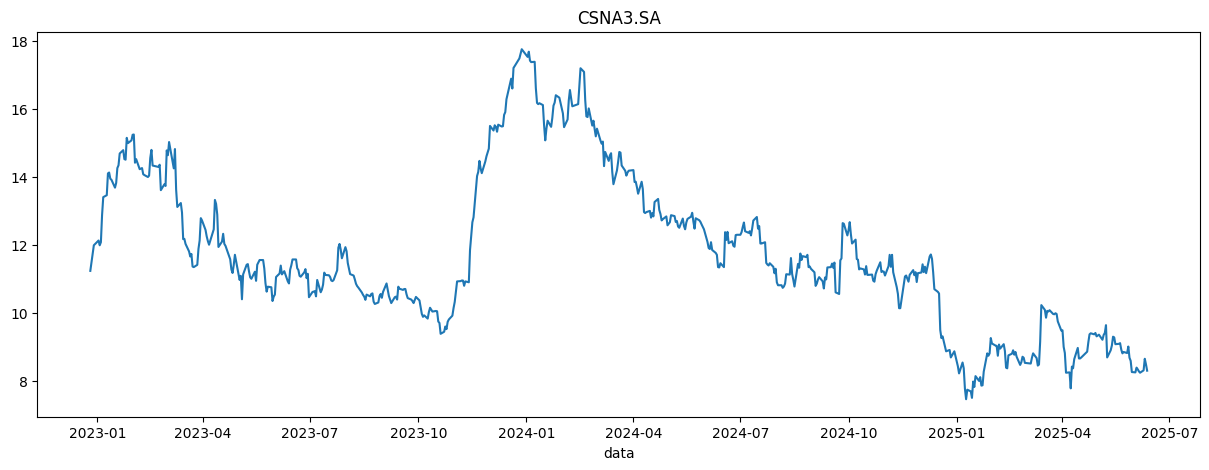

In [7]:
fig, ax = plt.subplots()
df_base['close'].plot(ax=ax, figsize=(15, 5), title=papel)

In [8]:
date(2024,1,1)

datetime.date(2024, 1, 1)

<Axes: title={'center': 'CSNA3.SA'}, xlabel='data'>

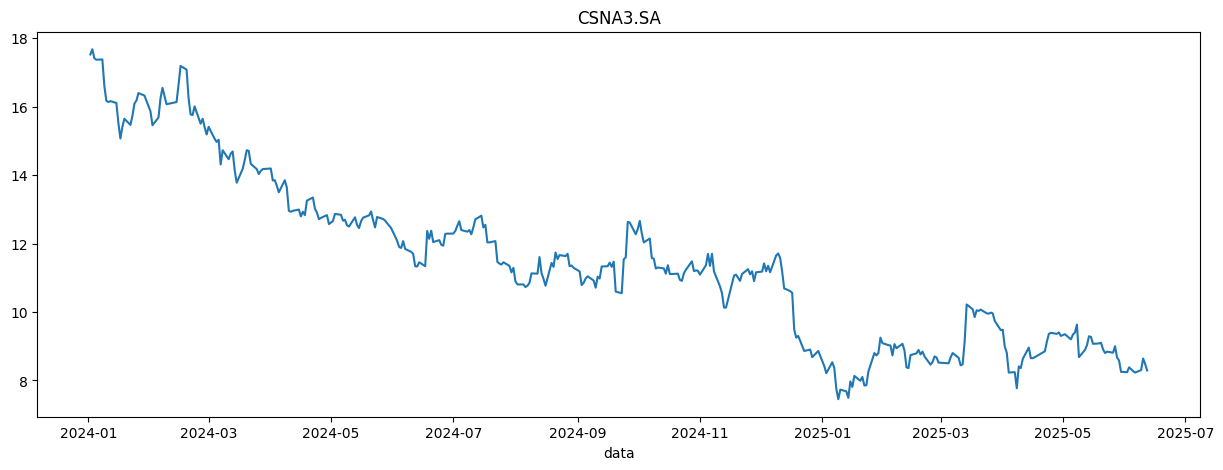

In [9]:
fig, ax = plt.subplots()
df_base[date(2024,1,1):]['close'].plot(ax=ax, figsize=(15, 5), title=papel)

In [10]:
df_base = df_base[date(2024,1,1):].copy()

## Verificação da volatilidade recente

In [11]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-05-30,0.358847,0.043497,0.370000,0.044848
2025-06-02,0.351786,0.042693,0.260000,0.031553
2025-06-03,0.345230,0.041197,0.260000,0.031026
2025-06-04,0.344142,0.041314,0.330000,0.039616
2025-06-05,0.338132,0.040887,0.260000,0.031439
2025-06-06,0.326837,0.039713,0.180000,0.021871
2025-06-09,0.317063,0.038200,0.190001,0.022892
2025-06-10,0.326558,0.037796,0.450000,0.052083
2025-06-11,0.325376,0.038370,0.310000,0.036557


In [12]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 3.81%
Valorização sugerida: 5.71%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [13]:
valorizacao = -0.06
DIAS_FUTURO = 6  # dias futuros para buscar a valorização

In [14]:
df = pp.calcular_target(df_base, x_pct=valorizacao, dias_futuro=DIAS_FUTURO)

In [15]:
df['Target'].value_counts(normalize=True)

Target
0.0    0.761236
1.0    0.238764
Name: proportion, dtype: float64

In [16]:
# Preparar X e y para treino
DIAS_JANELA_X = 15  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True)    

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

Colunas removidas por NaN: []


In [17]:
X_train.tail()

,close_mean,close_std,close_max,close_min,close_trend,retorno_desde_mudanca_close,close_amplitude,close_dist_min,close_ult_vs_mm_janela,close_vs_mm20,mm5_vs_mm20,retorno_mean,retorno_std,retorno_acumulado,dias_alta_pct,dias_queda_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,atr_ultimo,atr_pct_ultimo,rsi_mean,rsi_std,rsi_ultimo,macd_mean,macd_std,macd_ultimo,macd_std_norm_atr,macd_ultimo_norm_atr,macd_signal_mean,macd_signal_std,macd_signal_ultimo,macd_signal_std_norm_atr,macd_signal_ultimo_norm_atr,macd_hist_mean,macd_hist_std,macd_hist_ultimo,macd_hist_std_norm_atr,macd_hist_ultimo_norm_atr,atr_mean,atr_std,atr_pct_mean,atr_pct_std,tr_mean,tr_std,tr_ultimo,tr_std_norm_atr,tr_ultimo_norm_atr,tr_pct_mean,tr_pct_std,tr_pct_ultimo,close_std_norm_atr,close_amplitude_norm_atr,rsi_sobrecomprado_70,rsi_sobrevendido_30,macd_acima_sinal,macd_cruzou_sinal_para_cima,macd_conf_ultimo,macd_conf_mean,macd_hist_abs_ultimo,macd_hist_abs_mean,selic_ultimo,ipca_ultimo,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,ibov_std,retorno_desde_mudanca_ibov,ibov_amplitude,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean
2025-01-16,8.180667,0.515855,8.90,7.45,-0.099857,0.0,1.45,0.360000,-0.370667,-0.091438,-0.100047,-0.010911,0.037647,-0.118510,0.333333,0.666667,0.033180,-0.032956,1.197727e+07,3.083093e+06,230810.357143,0.184778,0.428329,0.054844,27.377636,3.595011,33.813024,-0.718771,0.117439,-0.773700,0.274179,-1.806319,-0.553920,0.184147,-0.764242,0.429919,-1.784240,-0.164851,0.077431,-0.009457,0.180775,-0.022080,0.450850,0.015177,0.055244,0.002654,0.402667,0.108131,0.29,0.252449,0.677050,0.049420,0.013748,0.037132,1.204342,3.385245,0,0,0,0,0.009457,0.164851,0.009457,0.164851,12.25,0.16,6.0322,-0.011134,0.057060,-0.005752,3.710714,1084.319857,0.000000,4117.0,0.629227,2.116890,-0.009017
2025-01-17,8.132000,0.480405,8.90,7.45,-0.081714,0.0,1.45,0.680000,-0.002000,-0.040368,-0.077432,-0.005025,0.038442,-0.086517,0.400000,0.600000,0.034479,-0.031361,1.275349e+07,3.914236e+06,418121.428571,0.700202,0.425592,0.052348,28.306138,4.688123,39.356406,-0.735122,0.095445,-0.715948,0.224264,-1.682242,-0.590160,0.164251,-0.754583,0.385935,-1.773022,-0.144962,0.088807,0.038635,0.208667,0.090780,0.447170,0.014049,0.055116,0.002749,0.399333,0.107668,0.39,0.252984,0.916371,0.049307,0.013753,0.047970,1.128793,3.407022,0,0,1,1,0.038635,0.150113,0.038635,0.150113,12.25,0.16,6.0609,-0.011549,0.058025,0.000000,74.760714,1214.773759,0.000000,4117.0,0.648824,2.259328,-0.007530
2025-01-20,8.071333,0.431457,8.86,7.45,-0.063321,0.0,1.41,0.540000,-0.081333,-0.042368,-0.055792,-0.006474,0.038467,-0.079493,0.333333,0.666667,0.040471,-0.029947,1.252209e+07,4.130389e+06,230257.857143,-0.409404,0.410906,0.051428,29.080366,5.249463,37.862328,-0.744395,0.080097,-0.673710,0.194926,-1.639571,-0.621007,0.143058,-0.738409,0.348153,-1.797024,-0.123387,0.097981,0.064698,0.238451,0.157453,0.442658,0.014106,0.054960,0.002894,0.384000,0.115993,0.22,0.282285,0.535402,0.047772,0.014845,0.027534,1.050013,3.431438,0,0,1,0,0.064698,0.137165,0.064698,0.137165,12.25,0.16,6.0498,-0.011758,0.058579,0.000000,153.867857,1335.934326,0.001577,4117.0,0.637481,2.247545,-0.008311
2025-01-21,8.032667,0.397680,8.86,7.45,-0.045214,0.0,1.41,0.650001,0.067334,-0.021030,-0.033116,-0.003909,0.038446,-0.085779,0.400000,0.600000,0.036021,-0.030528,1.269878e+07,4.083401e+06,175650.714286,0.017129,0.407985,0.050368,30.090531,5.767121,39.796220,-0.746261,0.076648,-0.624166,0.187870,-1.529875,-0.646058,0.121587,-0.715560,0.298019,-1.753890,-0.100203,0.105149,0.091395,0.257728,0.224015,0.438754,0.015092,0.054734,0.003118,0.388000,0.114280,0.37,0.280109,0.906898,0.048436,0.014485,0.045679,0.974743,3.456013,0,0,1,0,0.091395,0.126167,0.091395,0.126167,12.25,0.16,6.0440,-0.010741,0.054872,-0.000959,224.503571,1537.141246,0.008075,4805.0,0.661357,2.298603,-0.009926
2025-01-22,7.965333,0.326778,8.53,7.45,-0.026143,0.0,1.08,0.400000,-0.115333,-0.

In [22]:
modelo = RandomForestClassifier(n_estimators=200,
                                        max_depth=3,
                                        min_samples_leaf=60,
                                        max_features='sqrt',
                                        random_state=42,
                                        n_jobs=-1,
                                        class_weight='balanced'

                                        )
modelo.fit(X_train.values, y_train.values)

tr.comparar_auc_conjuntos(modelo, X_train, y_train, X_validacao, y_validacao)


AUC no treino: 0.827
AUC na validação: 0.575
Diferença AUC (Treino - Validação): 0.253
PROVÁVEL OVERFITTING


(np.float64(0.8273215189107271),
 np.float64(0.5746245563870915),
 np.float64(0.2526969625236356))

Avaliar e logar modelo
MLflow Run ID: f58d55d96f4c4062934e00b9b59324ee para CSNA3.SA_15dias_x_-0.06val_6dias_alvo
AUC no treino: 0.795
AUC na validação: 0.594

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.827
  Precisão média (em 151 janelas com previsão positiva): 0.498
  Recall médio: 0.541

Threshold Ideal Selecionado: 0.54
  Precisão Média Esperada: 80.54%
  Recall Médio Esperado: 34.67%
  Janelas Usadas para Precisão: 116.0

Threshold ideal baseado em recall mínimo: 0.54

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.215
Recall médio: 0.690
Sinais de compra presentes na vallidação: 21.0
Sinais de compra previstos na validação: 54
Modelo CSNA3.SA_15dias_x_-0.06val_6dias_alvo salvo na run f58d55d96f4c4062934e00b9b59324ee


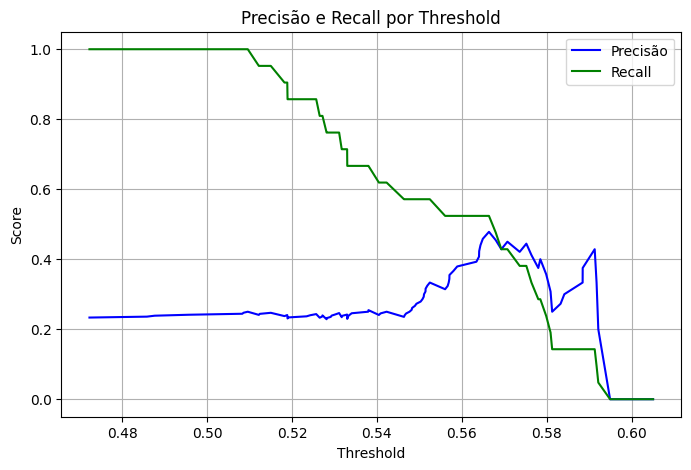

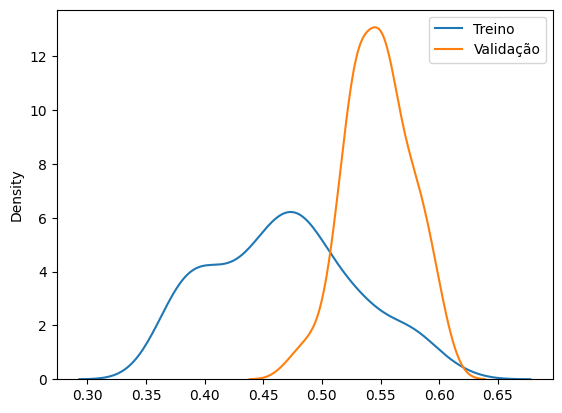

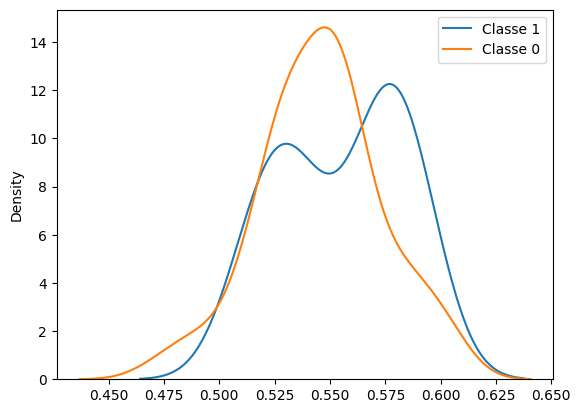

In [23]:
recall_minimo = 0.3  # mínimo de recall para considerar o modelo bom
resultado = tr.avaliar_e_logar_modelo(modelo, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

In [69]:
from sklearn.calibration import CalibratedClassifierCV


calibrated_model = CalibratedClassifierCV(modelo, method='isotonic', cv=5)
calibrated_model.fit(X_train.values, y_train.values)

CalibratedClassifierCV(cv=5,
                       estimator=RandomForestClassifier(class_weight='balanced',
                                                        max_depth=4,
                                                        min_samples_leaf=60,
                                                        n_estimators=200,
                                                        n_jobs=-1,
                                                        random_state=42),
                       method='isotonic')

Avaliar e logar modelo
MLflow Run ID: c3ca66d402b440abb597ba0fd79ee0bb para CSNA3.SA_15dias_x_0.06val_6dias_alvo
AUC no treino: 0.836
AUC na validação: 0.754

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.869
  Precisão média (em 0 janelas com previsão positiva): 0.000
  Recall médio: 0.000
Nenhum threshold atendeu ao recall mínimo de 0.30. Seguindo com 0.5

Threshold ideal baseado em recall mínimo: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 0 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 21.0
Sinais de compra previstos na validação: 0
Modelo CSNA3.SA_15dias_x_0.06val_6dias_alvo salvo na run c3ca66d402b440abb597ba0fd79ee0bb


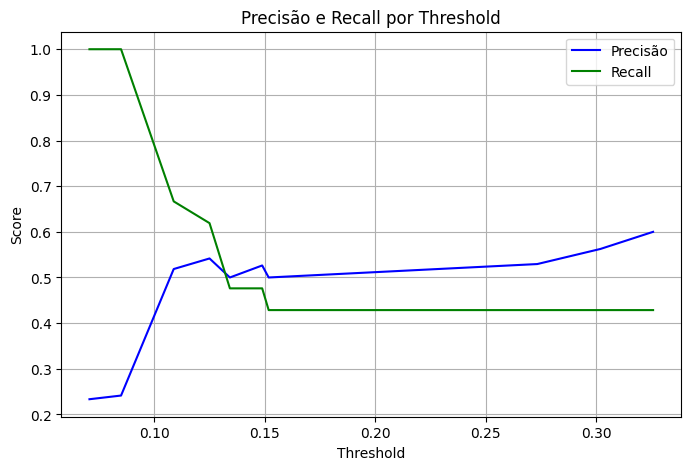

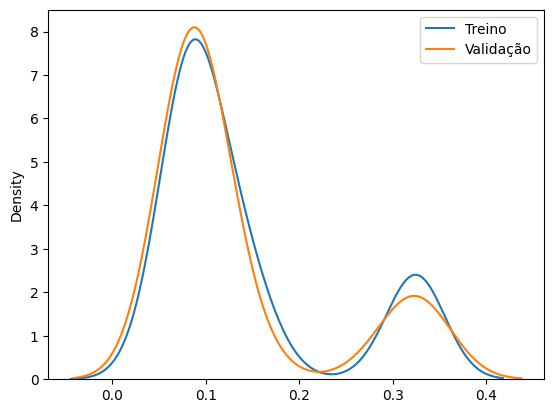

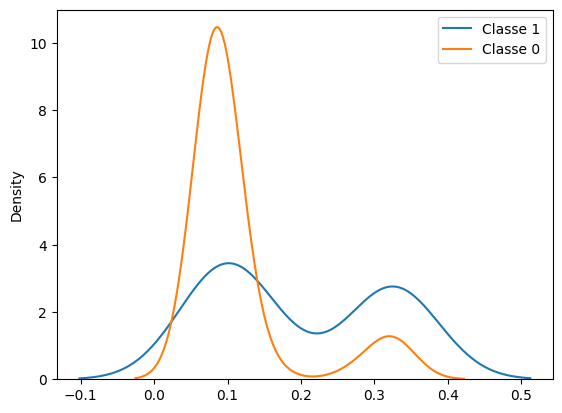

In [70]:
recall_minimo = 0.3  # mínimo de recall para considerar o modelo bom
resultado = tr.avaliar_e_logar_modelo(calibrated_model, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

## Eliminação por correlação

In [78]:
X_filtrado, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
X_validacao_filtrado = X_validacao[X_filtrado.columns]
print("Features removidas por alta correlação:", removidas)

Features removidas por alta correlação: ['close_amplitude', 'macd_conf_mean', 'macd_signal_std', 'macd_hist_ultimo', 'macd_std', 'close_mean', 'close_amplitude_norm_atr', 'macd_ultimo', 'close_max', 'retorno_acumulado', 'macd_signal_ultimo_norm_atr', 'macd_signal_ultimo', 'ibov_amplitude', 'macd_conf_ultimo']


In [80]:
modelo_filtrado = RandomForestClassifier(n_estimators=200,
                                        max_depth=4,
                                        min_samples_leaf=60,
                                        max_features='sqrt',
                                        random_state=42,
                                        n_jobs=-1,
                                        class_weight='balanced'
                                        )
modelo_filtrado.fit(X_filtrado.values, y_train.values)
tr.comparar_auc_conjuntos(modelo_filtrado, X_filtrado, y_train, X_validacao_filtrado, y_validacao)

AUC no treino: 0.928
AUC na validação: 0.746
Diferença AUC (Treino - Validação): 0.182
PROVÁVEL OVERFITTING


(np.float64(0.9279506555951795),
 np.float64(0.745886285032315),
 np.float64(0.1820643705628645))

In [82]:
# Importâncias
importancias = pd.Series(modelo_filtrado.feature_importances_, index=X_filtrado.columns)
importancias = importancias.sort_values(ascending=False)


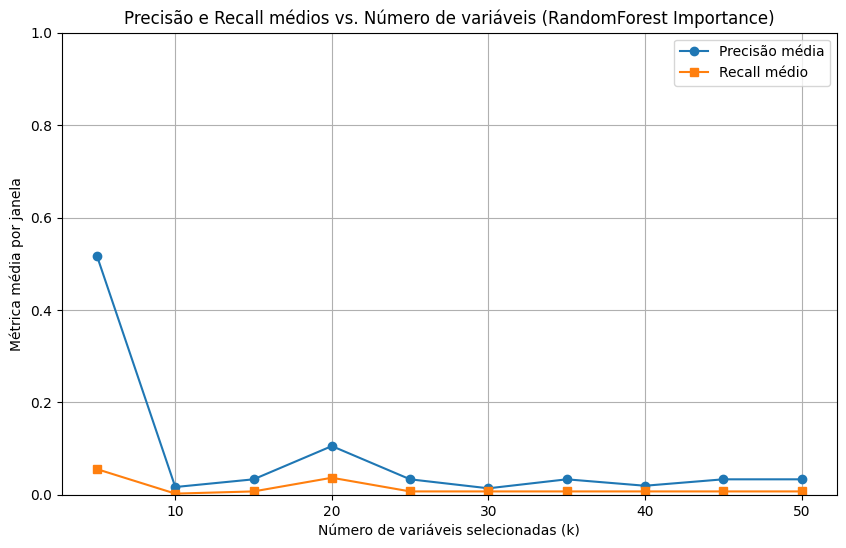

In [83]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            modelo.fit(X_train[colunas_selecionadas], y_train)

            y_pred = modelo.predict(X_val_teste)

            prec = precision_score(y_val_teste, y_pred, zero_division=0)
            rec = recall_score(y_val_teste, y_pred, zero_division=0)

            precisões.append(prec)
            recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()


# Features reduzidas

In [56]:
n_features = 35
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['rsi_ultimo',
 'atr_std',
 'close_ult_vs_mm_janela',
 'retorno_acumulado',
 'close_min',
 'tr_std',
 'retorno_mean',
 'close_vs_mm20',
 'close_mean',
 'close_amplitude_norm_atr',
 'close_dist_min',
 'atr_ultimo',
 'close_trend',
 'alpha_papel_vs_ibov_mean',
 'ibov_amplitude',
 'macd_ultimo_norm_atr',
 'beta_papel_ibov',
 'atr_pct_mean',
 'atr_mean',
 'dolar_ultimo',
 'mm5_vs_mm20',
 'tr_mean',
 'tr_pct_std',
 'macd_ultimo',
 'macd_signal_mean',
 'close_max',
 'dolar_trend',
 'dolar_std',
 'ipca_ultimo',
 'tr_pct_mean',
 'macd_signal_ultimo_norm_atr',
 'macd_signal_ultimo',
 'macd_hist_mean',
 'macd_hist_ultimo_norm_atr',
 'atr_pct_ultimo']

In [57]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [64]:
modelo_reduzido = RandomForestClassifier(n_estimators=200,
                                        max_depth=4,
                                        #min_samples_split=50,
                                        min_samples_leaf=80,                                        
                                        max_features='sqrt',
                                        random_state=42,
                                        n_jobs=-1
                                        )
modelo_reduzido.fit(X_train_reduzido.values, y_train.values)
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.783
AUC na validação: 0.654
Diferença AUC (Treino - Validação): 0.129
PROVÁVEL OVERFITTING


(np.float64(0.7825712222151053),
 np.float64(0.6536638521375036),
 np.float64(0.12890737007760178))

Avaliar e logar modelo
MLflow Run ID: c9bcea78aec14173b27386c33e212f50 para CSNA3.SA_30dias_x_0.06val_6dias_alvo
AUC no treino: 0.797
AUC na validação: 0.593

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.783
  Precisão média (em 0 janelas com previsão positiva): 0.000
  Recall médio: 0.000
Nenhum threshold atendeu ao recall mínimo de 0.30. Seguindo com 0.5

Threshold ideal baseado em recall mínimo: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 0 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 21.0
Sinais de compra previstos na validação: 0
Modelo CSNA3.SA_30dias_x_0.06val_6dias_alvo salvo na run c9bcea78aec14173b27386c33e212f50


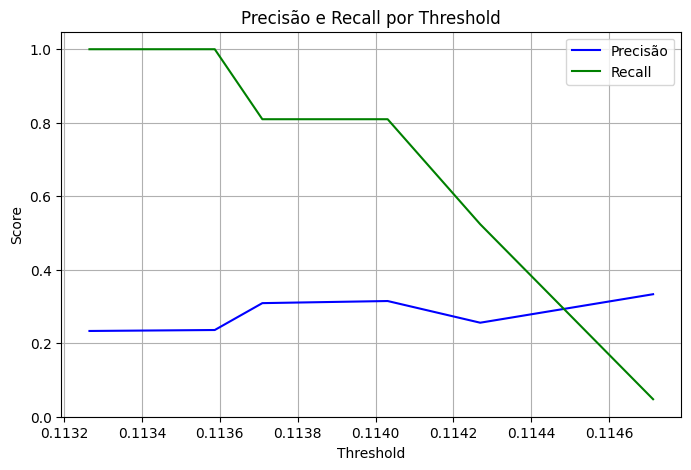

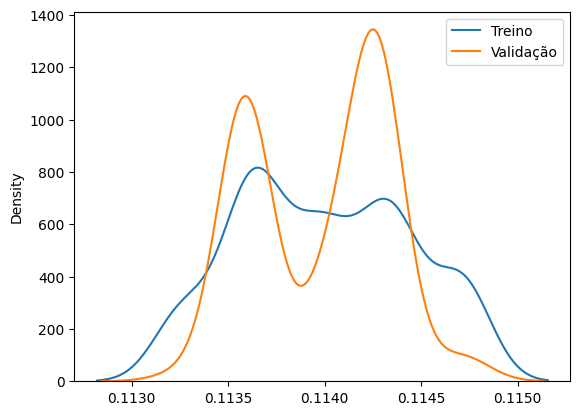

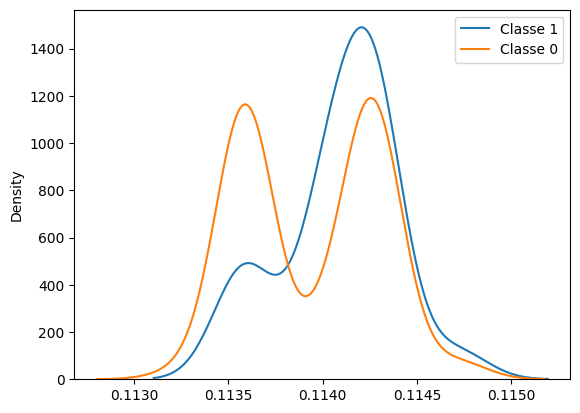

In [65]:
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=0.3)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

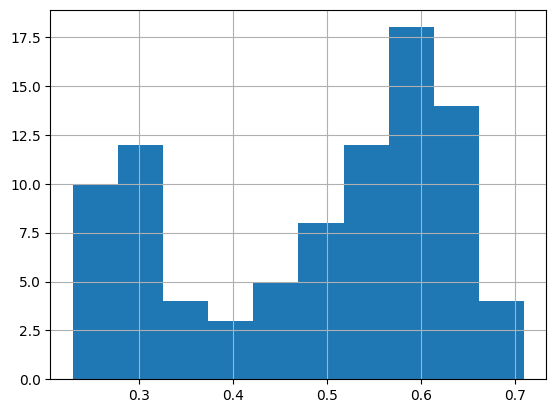

In [24]:
pd.Series(probas).hist()